In [23]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm import tqdm
from datasets import load_dataset
from scipy import ndimage

In [24]:
#Device 
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

Device: cuda
NVIDIA GeForce RTX 4090


In [25]:
#Import SAM2 
from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor

print("SAM2 imported successfully")

SAM2 imported successfully


In [26]:
#Load SAM2 
checkpoint_candidates = [
    "/home/zahranadeem/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2/checkpoints/sam2_hiera_small.pt",
    "/home/zahranadeem/thesis/sam2_repo/checkpoints/sam2_hiera_small.pt",
]

checkpoint = None

for p in checkpoint_candidates:
    if os.path.exists(p):
        checkpoint = p
        break

print("Checkpoint:", checkpoint)

assert checkpoint is not None, "SAM2 checkpoint not found."

config = "sam2_hiera_s.yaml"

sam2_model = build_sam2(
    config,
    checkpoint,
    device=device
)

predictor = SAM2ImagePredictor(sam2_model)

print("SAM2 loaded successfully")

Checkpoint: /home/zahranadeem/checkpoints/sam2_hiera_small.pt


SAM2 loaded successfully


In [27]:
#Load VegANN and create validation split 

dataset = load_dataset("simonMadec/VegAnn")

split_dataset = dataset["train"].train_test_split(
    test_size=0.2,
    seed=42
)

train_dataset = split_dataset["train"]
val_dataset = split_dataset["test"]

print("Train size:", len(train_dataset))
print("Validation size:", len(val_dataset))
print(val_dataset[0].keys())

Train size: 3020
Validation size: 755
dict_keys(['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'])


In [28]:
#Metric function 
def compute_iou_dice(pred_mask, gt_mask):
    pred = pred_mask.astype(bool)
    gt = gt_mask.astype(bool)

    intersection = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()

    iou = intersection / union if union > 0 else 0

    dice = (
        2 * intersection
    ) / (
        pred.sum() + gt.sum()
    ) if (pred.sum() + gt.sum()) > 0 else 0

    return iou, dice

In [29]:
#Auti-veg box function 
def get_vegetation_box_from_image_full(image, padding=0, percentile=60):
    """
    Best setting from ablation:
    percentile = 60
    padding = 0

    This function does NOT use GT mask.
    """

    img = image.astype(np.float32) / 255.0

    r = img[:, :, 0]
    g = img[:, :, 1]
    b = img[:, :, 2]

    exg = 2 * g - r - b

    threshold = np.percentile(exg, percentile)

    veg_mask = exg > threshold

    ys, xs = np.where(veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = image.shape[:2]

        box = np.array([
            W // 4,
            H // 4,
            3 * W // 4,
            3 * H // 4
        ])

        return box, veg_mask

    H, W = image.shape[:2]

    x1 = max(xs.min() - padding, 0)
    y1 = max(ys.min() - padding, 0)
    x2 = min(xs.max() + padding, W - 1)
    y2 = min(ys.max() + padding, H - 1)

    box = np.array([x1, y1, x2, y2])

    return box, veg_mask

In [30]:
#Positive point helper 
def get_positive_point_from_estimated_mask(estimated_veg_mask):
    ys, xs = np.where(estimated_veg_mask)

    if len(xs) == 0 or len(ys) == 0:
        H, W = estimated_veg_mask.shape
        return np.array([[W // 2, H // 2]])

    cx = int(xs.mean())
    cy = int(ys.mean())

    return np.array([[cx, cy]])

In [31]:
#SAM2 best prompt function 
def run_sam2_box_one_point_prompt(image, box, estimated_veg_mask, gt_mask=None):
    pos_point = get_positive_point_from_estimated_mask(estimated_veg_mask)
    point_labels = np.array([1])

    predictor.set_image(image)

    masks, scores, logits = predictor.predict(
        box=box,
        point_coords=pos_point,
        point_labels=point_labels,
        multimask_output=True
    )

    best_idx = scores.argmax()
    pred_mask = masks[best_idx] > 0

    if gt_mask is not None:
        iou_normal, _ = compute_iou_dice(pred_mask, gt_mask)
        iou_inv, _ = compute_iou_dice(~pred_mask, gt_mask)

        if iou_inv > iou_normal:
            pred_mask = ~pred_mask

    return pred_mask

In [32]:
#Checking one Validation image 
idx = 0

sample = val_dataset[idx]

image = np.array(sample["image"])
mask = np.array(sample["mask"])

# VegAnn: vegetation = 0, background = 255
gt_mask = mask == 0

auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
    image,
    padding=0,
    percentile=60
)

pred_mask = run_sam2_box_one_point_prompt(
    image,
    auto_box,
    estimated_veg_mask,
    gt_mask=gt_mask
)

iou, dice = compute_iou_dice(pred_mask, gt_mask)

print("Species:", sample["Species"])
print("Auto box:", auto_box)
print(f"IoU: {iou*100:.2f}%")
print(f"Dice: {dice*100:.2f}%")

Species: Wheat
Auto box: [  0   0 511 511]
IoU: 25.92%
Dice: 41.16%


In [33]:
print("GT unique:", np.unique(gt_mask))
print("Prediction unique:", np.unique(pred_mask))

print(gt_mask.dtype)
print(pred_mask.dtype)

GT unique: [False  True]
Prediction unique: [False  True]
bool
bool


In [34]:
intersection = np.logical_and(pred_mask, gt_mask).sum()
intersection_inverted = np.logical_and(~pred_mask, gt_mask).sum()

print("Normal intersection:", intersection)
print("Inverted intersection:", intersection_inverted)

Normal intersection: 52340
Inverted intersection: 1176


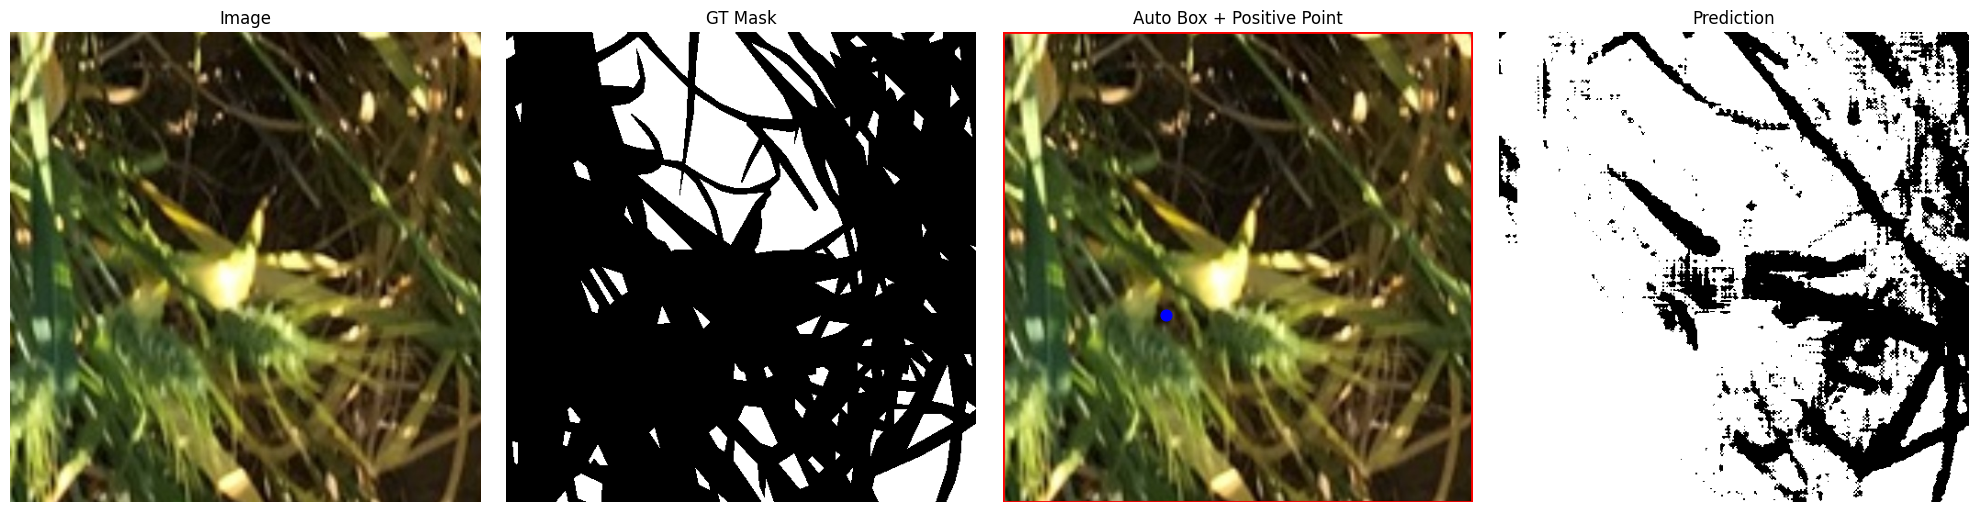

In [35]:
#Visualize 
import matplotlib.patches as patches

x1, y1, x2, y2 = auto_box
pos_point = get_positive_point_from_estimated_mask(estimated_veg_mask)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(image)
axes[0].set_title("Image")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("GT Mask")
axes[1].axis("off")

axes[2].imshow(image)
rect = patches.Rectangle(
    (x1, y1),
    x2 - x1,
    y2 - y1,
    linewidth=2,
    edgecolor="red",
    facecolor="none"
)
axes[2].add_patch(rect)
axes[2].scatter(
    pos_point[0][0],
    pos_point[0][1],
    c="blue",
    s=60
)
axes[2].set_title("Auto Box + Positive Point")
axes[2].axis("off")

axes[3].imshow(pred_mask, cmap="gray")
axes[3].set_title("Prediction")
axes[3].axis("off")

plt.tight_layout()
plt.show()

In [36]:
#Evaluation function 
def evaluate_best_prompt(N=None):
    if N is None:
        N = len(val_dataset)

    N = min(N, len(val_dataset))

    results = []

    for idx in tqdm(range(N), desc=f"Evaluating {N} images"):

        sample = val_dataset[idx]

        image = np.array(sample["image"])
        mask = np.array(sample["mask"])

        gt_mask = mask == 0

        if gt_mask.sum() == 0:
            continue

        auto_box, estimated_veg_mask = get_vegetation_box_from_image_full(
            image,
            padding=0,
            percentile=60
        )

        pred_mask = run_sam2_box_one_point_prompt(
            image,
            auto_box,
            estimated_veg_mask
        )

        iou, dice = compute_iou_dice(pred_mask, gt_mask)

        results.append({
            "idx": idx,
            "Species": sample["Species"],
            "IoU": iou,
            "Dice": dice
        })

    return pd.DataFrame(results)

In [37]:
#Run 500 validation images 
results_best_500 = evaluate_best_prompt(500)

mean_iou_500 = results_best_500["IoU"].mean()
mean_dice_500 = results_best_500["Dice"].mean()

print(f"500 images Mean IoU: {mean_iou_500*100:.2f}%")
print(f"500 images Mean Dice: {mean_dice_500*100:.2f}%")

Evaluating 500 images: 100%|██████████| 500/500 [01:33<00:00,  5.33it/s]

500 images Mean IoU: 23.51%
500 images Mean Dice: 28.78%


In [38]:
#Running full validation split 755 images 
results_best_full = evaluate_best_prompt(None)

mean_iou_full = results_best_full["IoU"].mean()
mean_dice_full = results_best_full["Dice"].mean()

print(f"Full validation Mean IoU: {mean_iou_full*100:.2f}%")
print(f"Full validation Mean Dice: {mean_dice_full*100:.2f}%")
print("Validation images evaluated:", len(results_best_full))

Evaluating 755 images: 100%|██████████| 755/755 [00:34<00:00, 22.02it/s]

Full validation Mean IoU: 22.84%
Full validation Mean Dice: 28.00%
Validation images evaluated: 753


In [42]:
#Final evaluation table 
final_eval_table = pd.DataFrame({
    "Evaluation Set": [
        "500 validation images",
        "Full validation split"
    ],
    "Mean IoU": [
        mean_iou_500,
        mean_iou_full
    ],
    "Mean Dice": [
        mean_dice_500,
        mean_dice_full
    ]
})

final_eval_percent = final_eval_table.copy()

final_eval_percent["Mean IoU"] = final_eval_percent["Mean IoU"].apply(
    lambda x: f"{x*100:.2f}%"
)

final_eval_percent["Mean Dice"] = final_eval_percent["Mean Dice"].apply(
    lambda x: f"{x*100:.2f}%"
)

final_eval_percent

,Evaluation Set,Mean IoU,Mean Dice
0,500 validation images,23.51%,28.78%
1,Full validation split,22.84%,28.00%


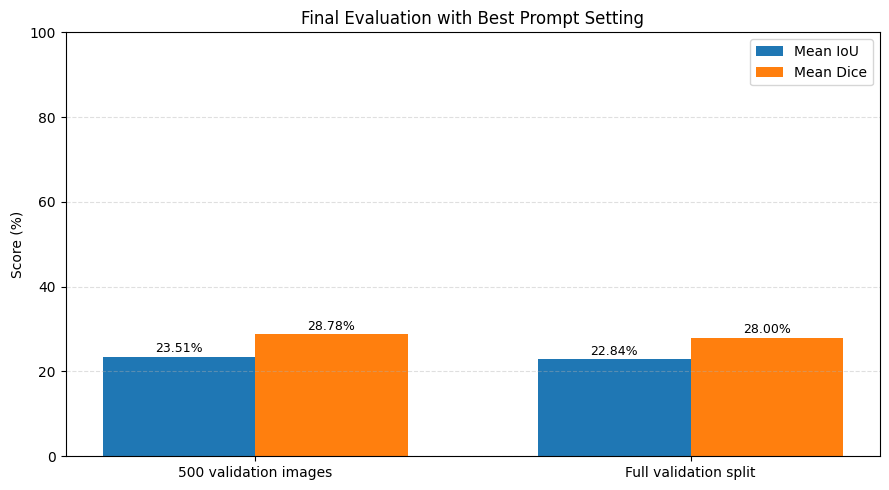

In [40]:
#PLot results 
sets = final_eval_table["Evaluation Set"].tolist()
iou_scores = [x * 100 for x in final_eval_table["Mean IoU"].tolist()]
dice_scores = [x * 100 for x in final_eval_table["Mean Dice"].tolist()]

x = np.arange(len(sets))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    iou_scores,
    width,
    label="Mean IoU"
)

plt.bar(
    x + width / 2,
    dice_scores,
    width,
    label="Mean Dice"
)

plt.xticks(x, sets)
plt.ylabel("Score (%)")
plt.title("Final Evaluation with Best Prompt Setting")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

for i, v in enumerate(iou_scores):
    plt.text(
        i - width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

for i, v in enumerate(dice_scores):
    plt.text(
        i + width / 2,
        v + 1,
        f"{v:.2f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()

plt.savefig(
    "final_best_prompt_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [41]:
#Saving results 
results_best_500.to_csv(
    "best_prompt_500_results.csv",
    index=False
)

results_best_full.to_csv(
    "best_prompt_full_validation_results.csv",
    index=False
)

final_eval_table.to_csv(
    "best_prompt_final_summary.csv",
    index=False
)

final_eval_percent.to_csv(
    "best_prompt_final_summary_percent.csv",
    index=False
)

print("Saved final evaluation results.")

Saved final evaluation results.
